# Platform Governance for GenAI Systems

A comprehensive guide to deploying, governing, and operating GenAI platforms at enterprise scale — covering platform architecture patterns, multi-tenant isolation strategies, compliance frameworks, audit trail design, and regulatory adaptation.

## Table of Contents

- [Module 01: Deployment Frameworks and Platform Architecture](#module-01)
- [Module 02: Multi-Tenant Architecture for GenAI Systems](#module-02)
- [Module 03: Enterprise Governance and Compliance](#module-03)
- [Module 04: Auditability and Transparency in GenAI Systems](#module-04)
- [Module 05: Regulatory Landscape and Future-Proofing GenAI Systems](#module-05)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

<a id="module-01"></a>
## Module 01: Deployment Frameworks and Platform Architecture

_Covers the prototype-to-production gap, the six-component GenAI reference architecture, CI/CD pipelines for AI artifacts, infrastructure-as-code practices, and internal developer platform design._

---

### The Prototype-to-Production Gap

Most GenAI prototypes succeed in isolation but fail when operationalised. The gap comes from four hard problems: reproducibility, cost unpredictability, governance absence, and observability blindness. A production platform must address all four explicitly.

### Traditional Software vs. GenAI Systems

Traditional software processes deterministic inputs through fixed algorithms with predictable cost. GenAI systems take non-linear, probabilistic paths: GPU-intensive inference, vector search, retrieval pipelines, and model-specific behaviour that no unit test fully captures.


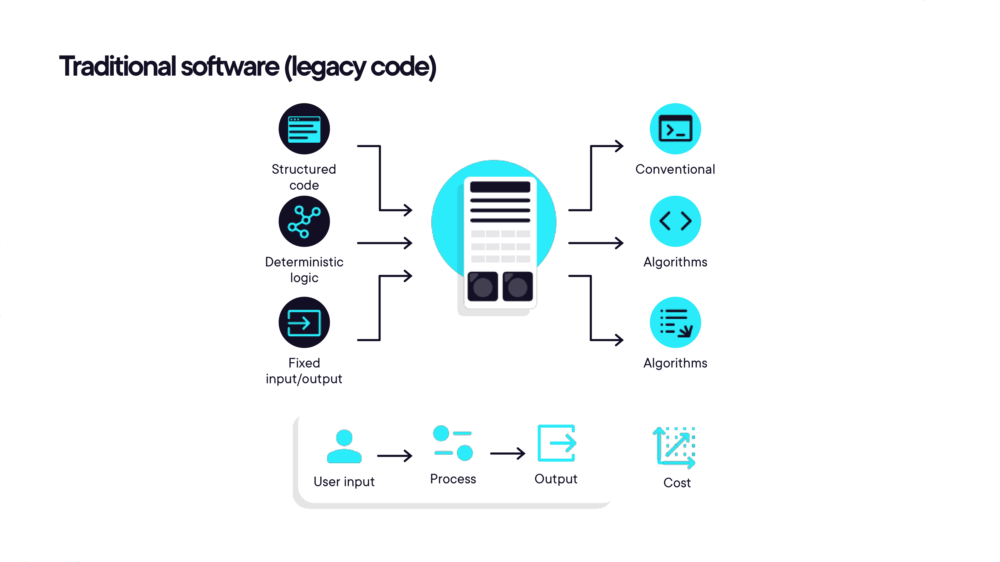

In [2]:
render_diagram(Path("assets/01-traditional-vs-genai-comparison.png"))


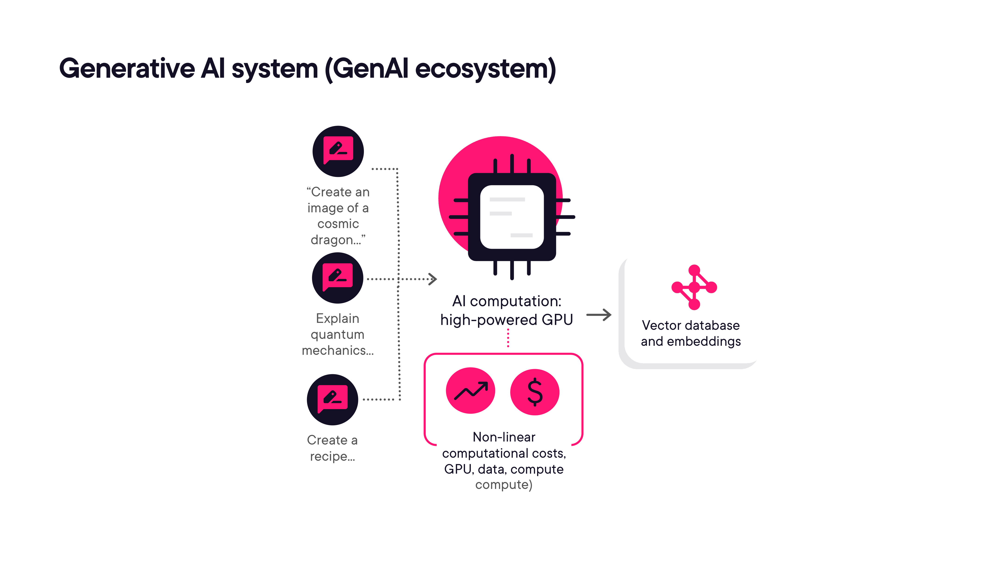

In [3]:
render_diagram(Path("assets/02-genai-ecosystem-architecture.png"))

### The Six-Component Reference Architecture

Every production GenAI system can be decomposed into six functional components:

1. **API Gateway** — controls access to everything behind it (auth, rate limiting, routing)
2. **Prompt Management** — versioned templates that tell the model what to say
3. **Model Serving** — assembles prompt + context + query, calls the LLM
4. **RAG Pipeline** — embed → vector search → re-rank → return relevant context
5. **Observability** — passively watches logs, metrics, and alerts across all other components
6. **Guardrails** — screens both input (PII scan, content filter, topic blocking) and output (hallucination check, toxicity, PII redaction)

The key insight: Observability is _passive_ (not in the request path), while Guardrails are _active_ (they can block or modify requests).


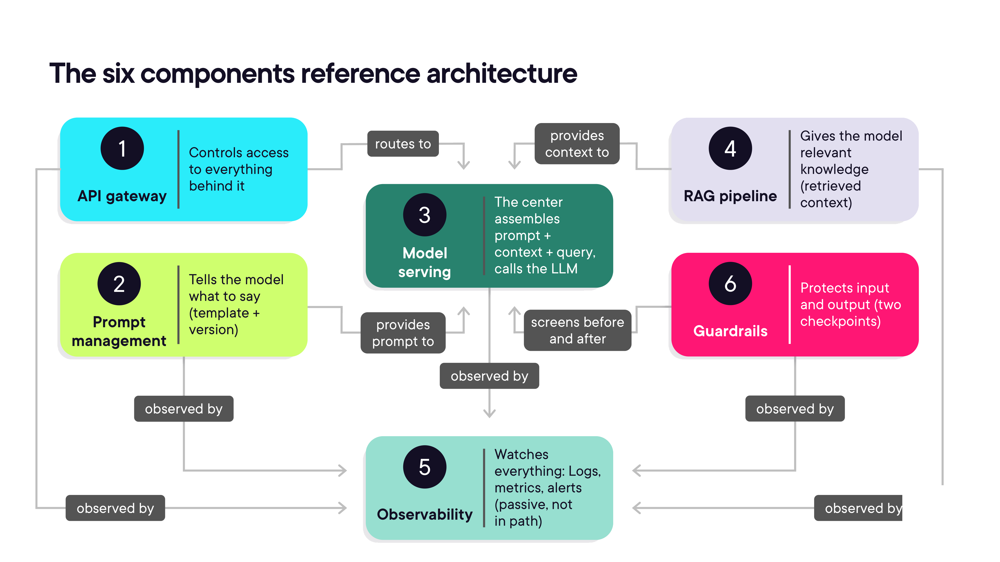

In [4]:
render_diagram(Path("assets/03-six-components-reference-architecture.png"))

### What Happens When a User Asks a Question?

Every request flows through three questions: **Identity** (who is asking, what are they allowed to do?), **Context** (what information does the model need to answer well?), and **Safety** (is the response appropriate to return?).

The detailed request flow through the six-component architecture:


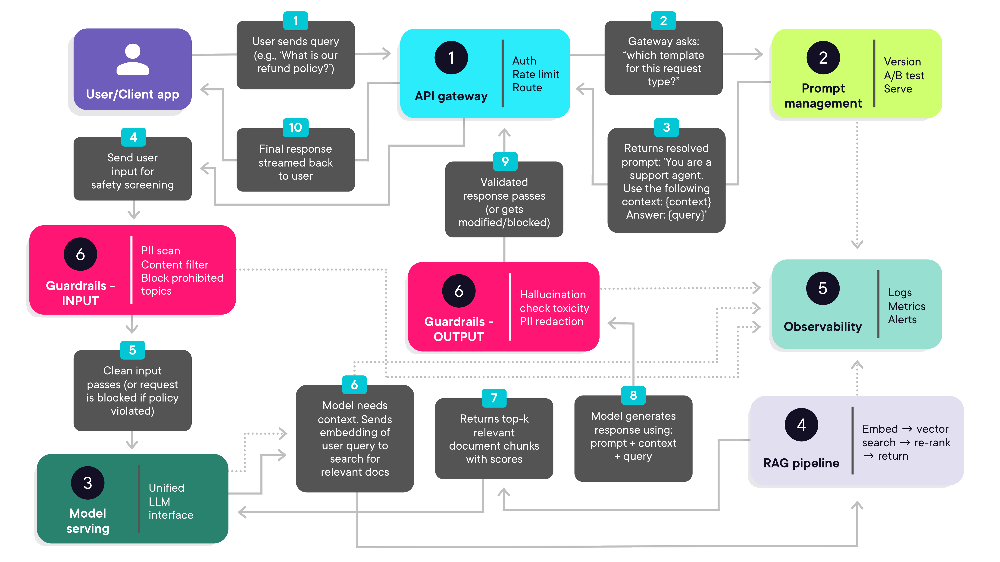

In [5]:
render_diagram(Path("assets/04-detailed-request-flow.png"))

### Platform Architecture Patterns for GenAI

#### Infrastructure Deployment Models

Three patterns for organising GenAI platform ownership:

| Pattern | Description | Trade-off |
|---|---|---|
| **Centralized** | Platform team owns everything; app teams consume | Consistent governance — bottleneck risk |
| **Federated** | Each app team owns their own platform | Fast and flexible — fragmented governance |
| **Hybrid (recommended)** | Shared governance core + team self-service extensions | Governance where it matters, autonomy where it doesn't |


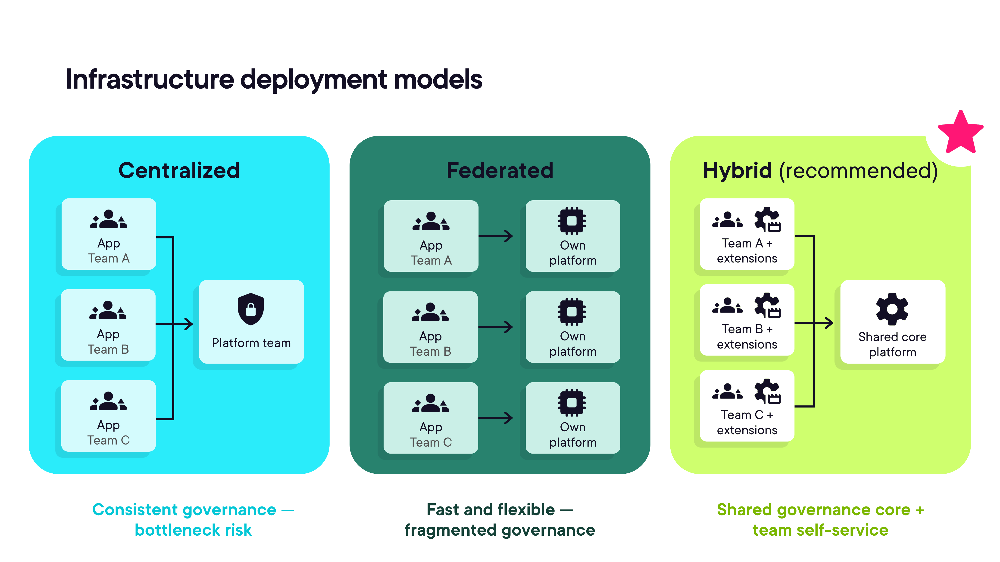

In [6]:
render_diagram(Path("assets/05-infrastructure-deployment-models.png"))

---

### CI/CD Pipelines and Infrastructure-as-Code for GenAI

#### The Four Artifact Types

GenAI systems have four independently versionable artifact types — any one of them, changed alone, can change what your system says to every user:

| Artifact | What it controls | Component | Rollback means... |
|---|---|---|---|
| **Code** | Application logic | All components | Redeploy previous version |
| **Prompts** | How the LLM responds | Prompt management | Revert prompt version |
| **Models** | What context the model receives | Model serving | Pin to previous model |
| **Retrieve data** | What context the model receives | RAG pipeline | Re-index from last known-good snapshot |

#### The GenAI Deployment Pipeline

A production deployment pipeline for GenAI has five stages:


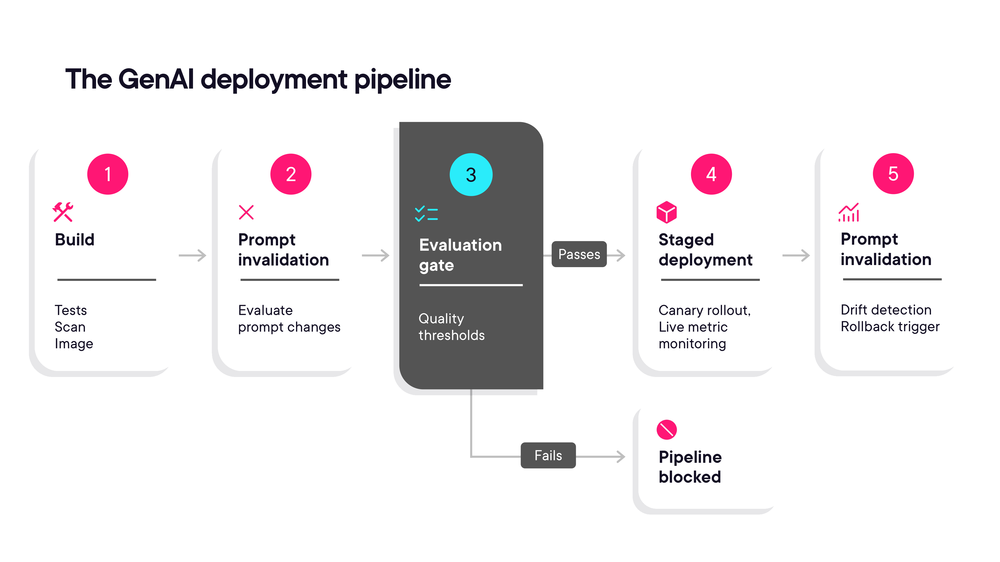

In [7]:
render_diagram(Path("assets/06-genai-deployment-pipeline.png"))

#### The Evaluation Gate

Three test categories must all pass defined thresholds before promotion to staging:

- **Functional tests** — answer correctness, faithfulness to retrieved context, relevancy
- **Performance tests** — latency percentiles, cost per request, throughput under load
- **Safety tests** — prompt injection resistance, jailbreak patterns, policy violation checks

Evaluation scores are not binary. A score between 0.7–1.0 may pass; below 0.7 fails; borderline scores require human review. Statistical confidence matters more than a single result.


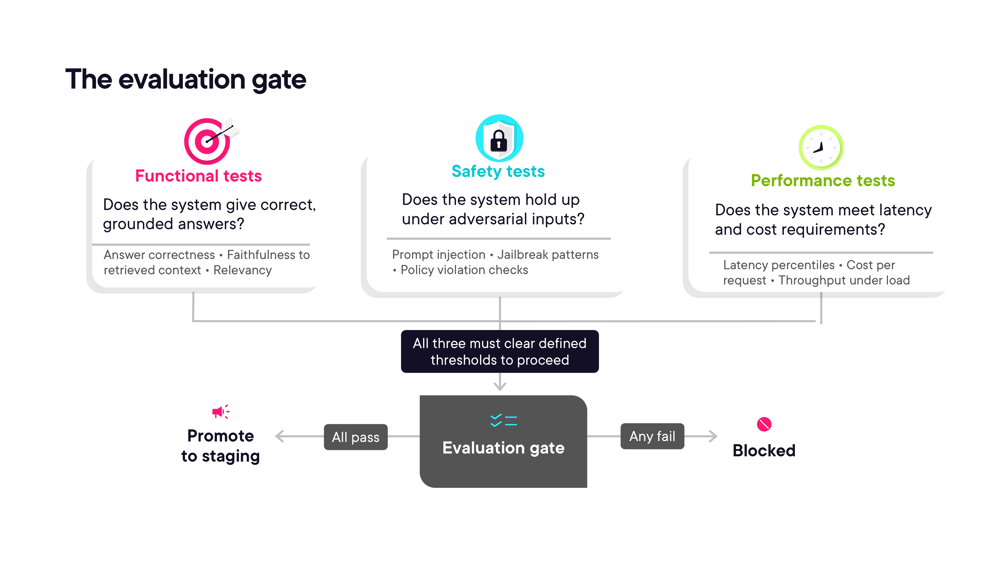

In [8]:
render_diagram(Path("assets/07-evaluation-gate.png"))

#### Why Infrastructure-as-Code Matters for GenAI

Manual configuration creates drift, undocumented changes, and compliance gaps. Everything that governs GenAI system behaviour must be codified:

- **What to codify**: model endpoints, vector stores, network policies, IAM roles, guardrails config, monitoring rules
- **How**: versioned in git, reviewed in PRs, applied through automation
- **Why it matters for compliance**: a guardrails config checked into git is compliance evidence; one set manually in a console is not

---

### Building Internal Developer Platforms (IDPs) for GenAI Teams

> An IDP is a self-service layer on top of governed infrastructure that gives application teams the ability to provision environments, deploy changes, and monitor usage — without depending on the platform team for every action.

Without an IDP, teams route around the platform to avoid bottlenecks, creating Shadow AI — GenAI usage without governance coverage. With an IDP, teams adopt the platform because it is faster than the alternative, and governance is enforced automatically.


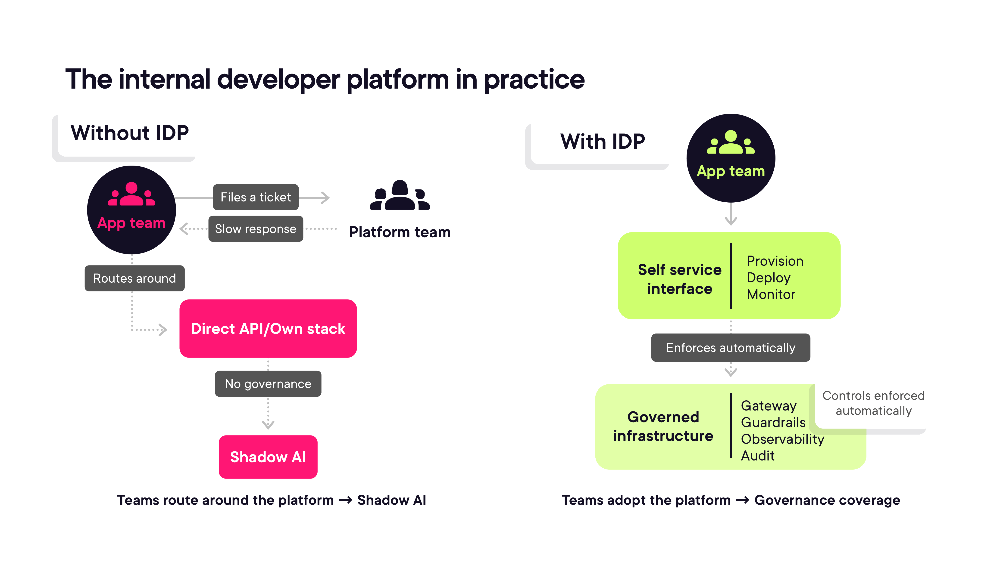

In [9]:
render_diagram(Path("assets/08-idp-in-practice.png"))

#### The Five IDP Capabilities

| Capability | What it gives the team |
|---|---|
| Self-service environment provisioning | Spin up a fully governed tenant environment |
| Prompt management interface | Create, version, test, and deploy prompts through a UI |
| Model catalog | Browse and select models by capability, cost, latency — no direct endpoint access needed |
| Cost and usage dashboards | Token consumption real-time visibility, spend, budget alerts |
| Compliance and policy status | Active guardrails, current policy settings, deployment compliance boundaries |

#### Permission Zones: What Teams Can and Cannot Do

Teams operate in three zones:

- **Self-service (no approval needed)**: select from approved model catalog, deploy prompts that pass the evaluation gate, configure RAG retrieval parameters, set cost alert thresholds
- **Requires lightweight review**: access a model in evaluation/not yet approved, request higher rate limits, adjust guardrail thresholds within permitted ranges
- **Blocked at infrastructure**: bypass the guardrails engine, direct access to model endpoints bypassing gateway, disable audit logging

> Goal: maximise the green zone to drive adoption — keep the red zone firm for governance.

<a id="module-02"></a>
## Module 02: Multi-Tenant Architecture for GenAI Systems

_Covers isolation strategies, per-tenant customization, resource quota management, and automated tenant onboarding and lifecycle management._

---

### Isolation Strategies and Tenant Customization

#### Why Multi-Tenancy is Hard in GenAI

Traditional SaaS multi-tenancy is solved with row-level security on a `tenant_id` column. GenAI systems have four independent failure dimensions — each of which can breach tenant boundaries separately:


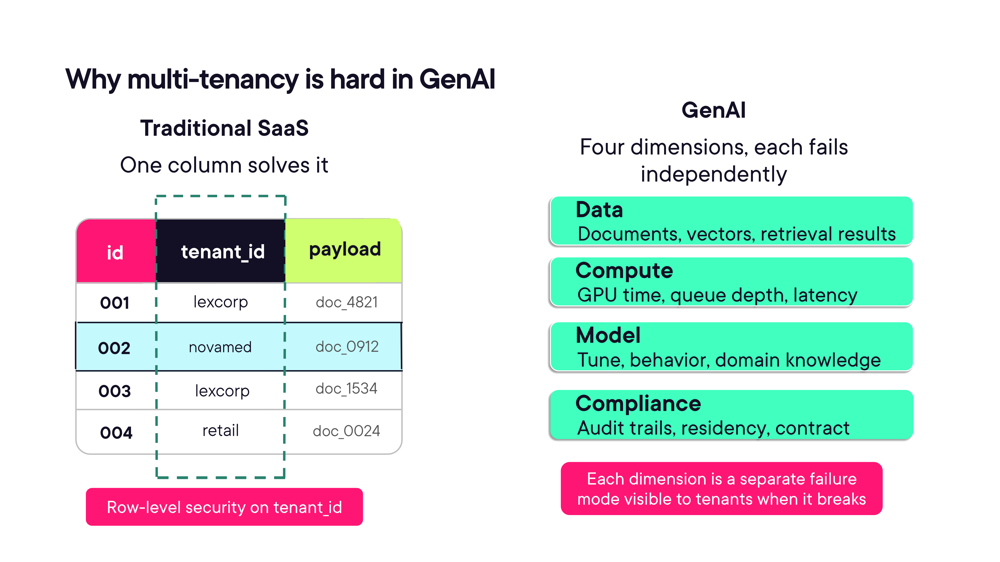

In [10]:
render_diagram(Path("assets/09-multitenant-challenge.png"))

#### The Four Dimensions of Isolation

| Dimension | What it means | Failure mode |
|---|---|---|
| **Data** | Documents and vectors never surface in another tenant's responses | Cross-tenant retrieval leakage |
| **Compute** | A traffic spike never steals another tenant's latency | Noisy-neighbour GPU saturation |
| **Model** | Tone and domain knowledge never bleed between tenants | Fine-tune or prompt contamination |
| **Compliance** | Audit trails, residency, and contractual separation per tenant | Regulatory breach from shared logging |

#### The Isolation Spectrum

Three deployment patterns, ordered from cheapest to most isolated:


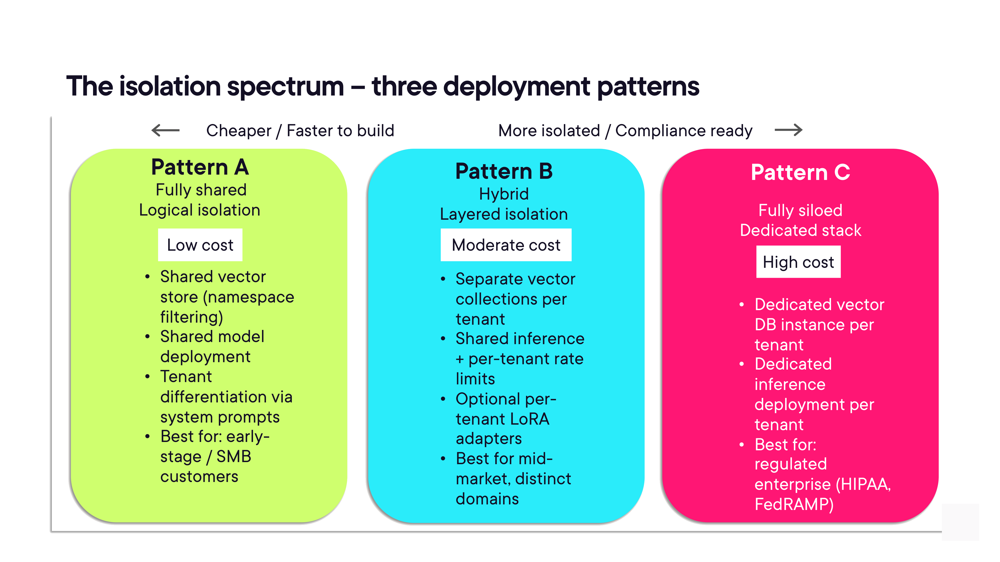

In [11]:
render_diagram(Path("assets/10-isolation-spectrum.png"))

#### Per-Tenant Customization

One platform can serve radically different tenants through three customization levers stacked on a shared foundation:

| Tenant | Vector namespace | Fine-tuning | System prompt | Guardrails |
|---|---|---|---|---|
| **LexCorp** (law firm) | 40K legal docs | LoRA: Legal Q&A | Formal, cite sources | Strict hallucination filter |
| **NovaMed** (healthcare) | 10K clinical guidelines | LoRA: Clinical language | Empathetic, plain language | PHI detection |
| **RetailPeak** (e-commerce) | 200K SKUs | None needed | Casual, link products | Standard guardrails |

The shared foundation (auth, logging, orchestration, foundation model) is invisible to each tenant — they experience a product built for them.


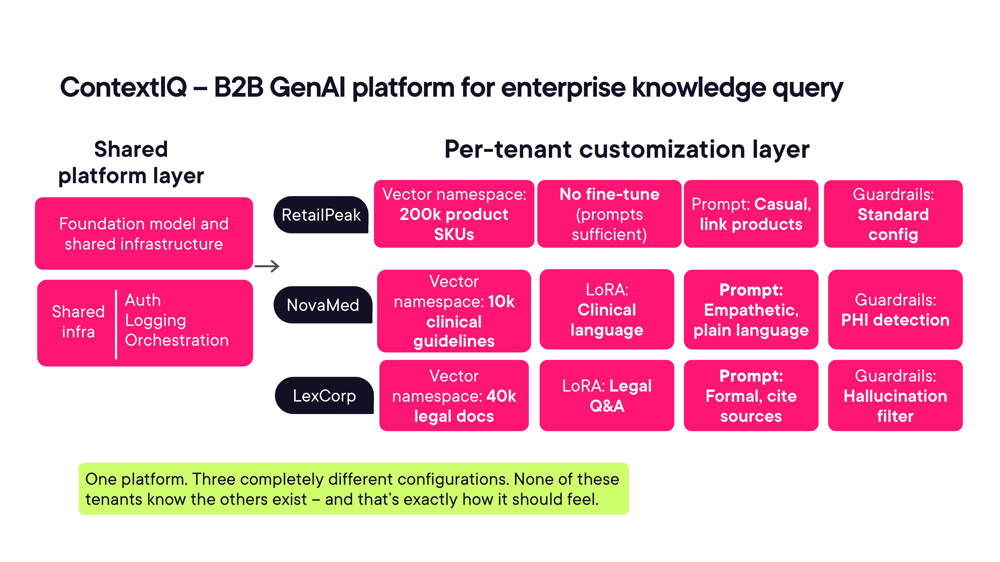

In [12]:
render_diagram(Path("assets/11-per-tenant-customization.png"))

#### The Three Customization Levers

The tenant config service is the single source of truth. It drives three levers:

1. **Retrieval** — isolated vector namespace, tenant embedding model, chunk size and metadata schema
2. **Configuration** — system prompt and tone, guardrail rules and PII config (versioned, hot-reloadable)
3. **Fine-tuning** — LoRA adapter with adapter versioning, A/B testing, and fallback to base model


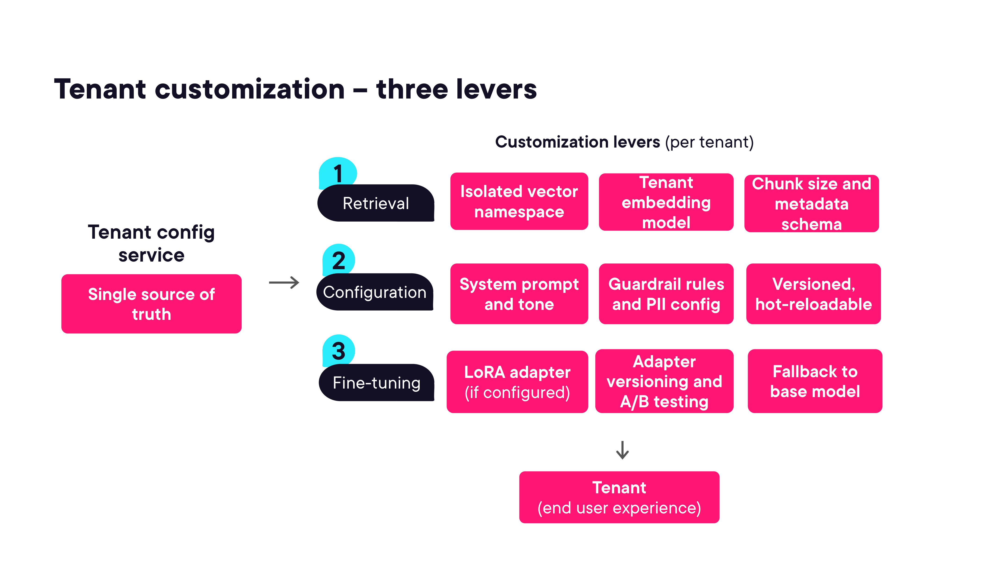

In [13]:
render_diagram(Path("assets/12-customization-levers.png"))

---

### Resource Allocation and Quota Management

#### The Noisy Neighbour Problem

Without isolation controls, one tenant's traffic spike — a bulk ingestion, a viral moment, a batch job — can saturate the shared GPU pool, push queue depth into overflow, and breach another tenant's SLA. The three tenants in the ContextIQ example illustrate exactly this: NovaMed's bulk ingestion, RetailPeak's viral spike, and LexCorp's latency-sensitive case review are all happening on the same infrastructure simultaneously.

#### Application-Layer Controls: Rate Limiting and Priority

Token-bucket rate limiting gives each tenant a per-tier bucket: requests consume tokens; the bucket refills at the configured rate; an empty bucket queues or rejects requests. Burst capacity absorbs spikes; refill rate caps sustained load.

A fair-share dequeue prevents starvation: enterprise traffic is served first, but free-tier tenants always receive a guaranteed slice.


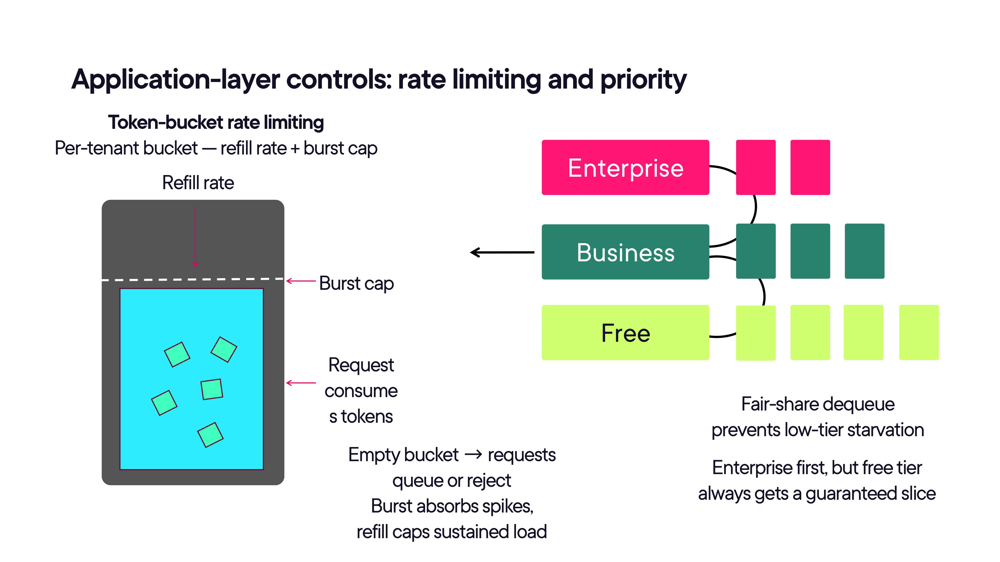

In [14]:
render_diagram(Path("assets/13-rate-limiting-controls.png"))

#### Infrastructure-Layer Controls: Compute Scheduling

At the Kubernetes layer, each tenant has a namespace with a resource quota and priority class. Low-priority pods (e.g., batch ingestion) are preemptible — they are evicted when high-priority interactive traffic arrives. Premium tenants can be pinned to dedicated node pools.


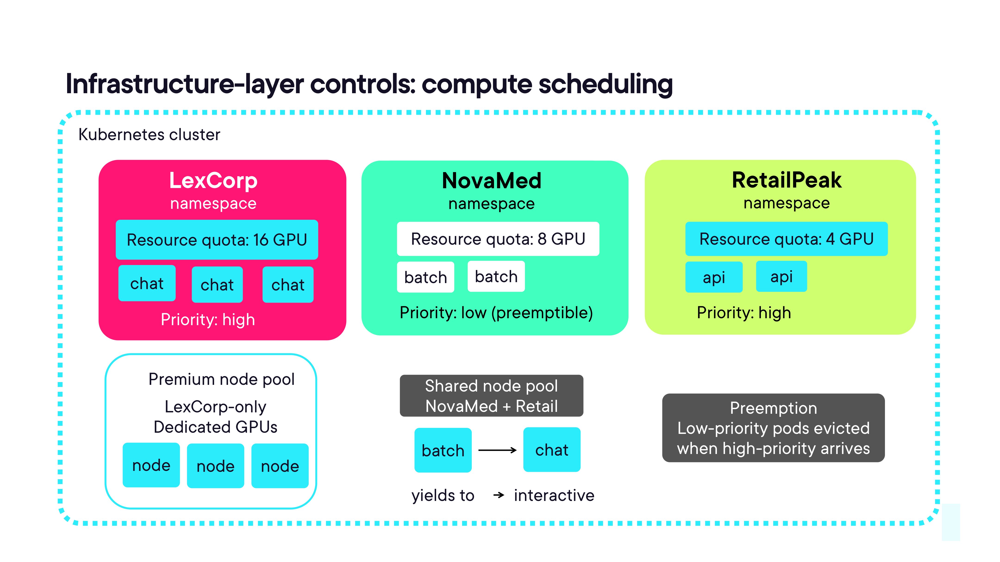

In [15]:
render_diagram(Path("assets/14-kubernetes-compute-scheduling.png"))

#### Cost Allocation Models

Three billing approaches, each with different trade-offs:

| Model | Description | Best for |
|---|---|---|
| **Per-token** | Charge input + output tokens consumed | Variable workloads, usage-based pricing |
| **Per-request** | Flat fee per API call | Standardised templates, fixed prompts |
| **Tiered subscription** | Fixed monthly fee for a usage tier, overages billed separately | Enterprise contracts, committed spend |

> Most mature platforms use a hybrid: tiered base + per-token metering for overages and cost attribution.

Additional controls: per-endpoint limits (`/embed` is cheap vs `/chat/completions` is expensive), time-of-day policies (batch throttled during peak hours), and soft caps (alert) vs. hard caps (reject).

#### Runtime Quota Architecture

The quota system works through three layers driven by the tenant config service:


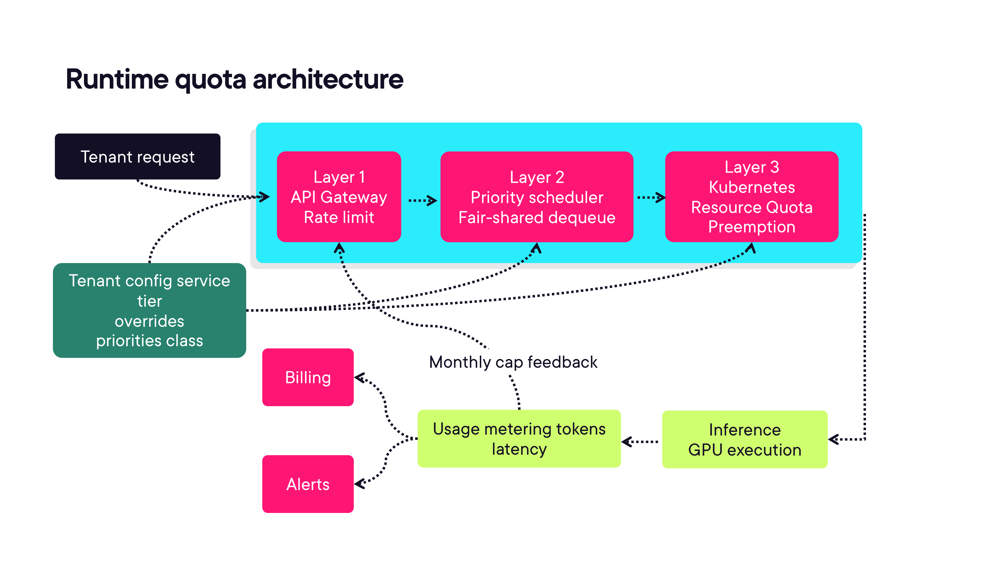

In [16]:
render_diagram(Path("assets/15-runtime-quota-architecture.png"))

---

### Automated Tenant Onboarding and Lifecycle Management

#### The Manual Onboarding Trap

Manual onboarding scales to three tenants but fails at forty. The failure modes are predictable: namespace naming conflicts, secrets copy-pasted from the wrong tenant, tenants with no billing records, days-long wait times, and bus-factor of one DevOps engineer.

#### The Tenant Lifecycle

Four phases must complete before a tenant goes active:

1. **Provisioning** — create Kubernetes namespace, generate secrets and API keys, configure model endpoint, initialize vector store
2. **Configuration** — write tenant config, set feature flags, load prompt templates
3. **Access control** — create RBAC roles, issue API keys, set up audit logging
4. **Billing** — assign pricing tier, write metering hooks, connect invoice pipeline

> **The golden rule: A tenant must never be able to discover that other tenants exist.**


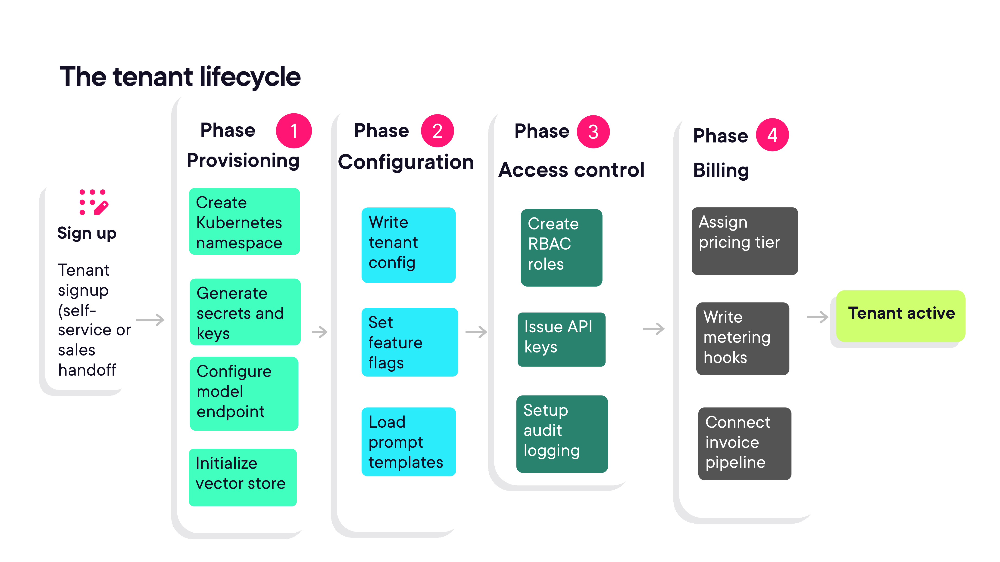

In [17]:
render_diagram(Path("assets/16-tenant-lifecycle.png"))

#### What Gets Provisioned

A single `POST /tenants` call to the control plane triggers fully automated creation of:

- **Kubernetes**: namespace, resource quota, limit range, network policy
- **Secrets**: API keys in vault, tenant-scoped encryption key, rotation schedule
- **Data**: vector namespace, audit log stream, usage metering topic
- **Identity**: RBAC roles (tenant-admin, tenant-user), service accounts

No manual steps, no console clicks, no SSH — and all operations are idempotent.


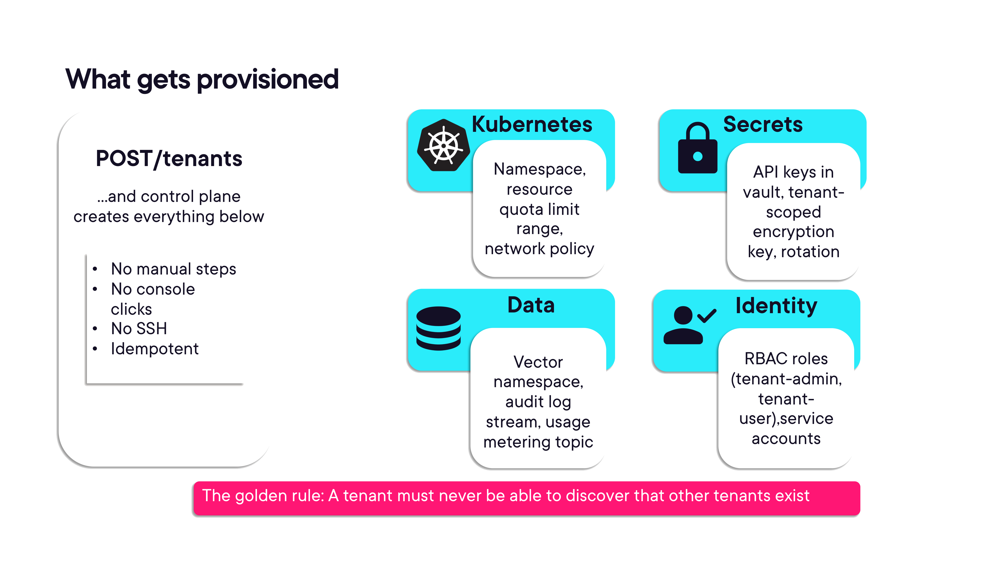

In [18]:
render_diagram(Path("assets/17-tenant-provisioning.png"))

#### The Control Plane

The control plane coordinates all tenant lifecycle operations through synchronous services (provisioning engine, config store, IAM service, billing service) and an async event bus that fans out `tenant.created` / `tenant.suspended` events to downstream subscribers (notifications, CS tooling, analytics). Every operation across every service feeds into an immutable, cross-cutting audit log.


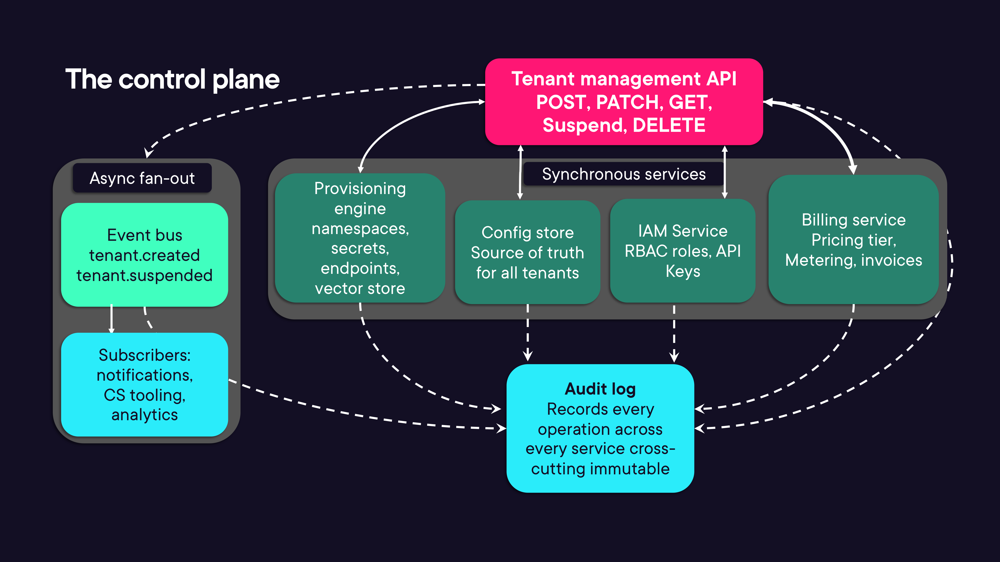

In [19]:
render_diagram(Path("assets/18-control-plane.png"))

<a id="module-03"></a>
## Module 03: Enterprise Governance and Compliance

_Covers governance frameworks and approval workflows, access controls, compliance tracking, and the complete model governance lifecycle._

---

### Why GenAI Governance Cannot Be Bolted On

| Dimension | Traditional software | Generative AI |
|---|---|---|
| Outputs | Deterministic | Non-deterministic |
| Failures | Reproducible, debuggable | Stochastic, probabilistic |
| Test coverage | Gives confidence | Evaluation is probabilistic |
| Security | Protect the perimeter | Protect data, prompts, and outputs |
| Compliance | Check a box once | Continuous monitoring |

Governance that works for traditional software doesn't translate. GenAI compliance must be designed into the architecture — not retrofitted.

### Governance Frameworks and Approval Workflows

#### The Four Pillars of GenAI Governance


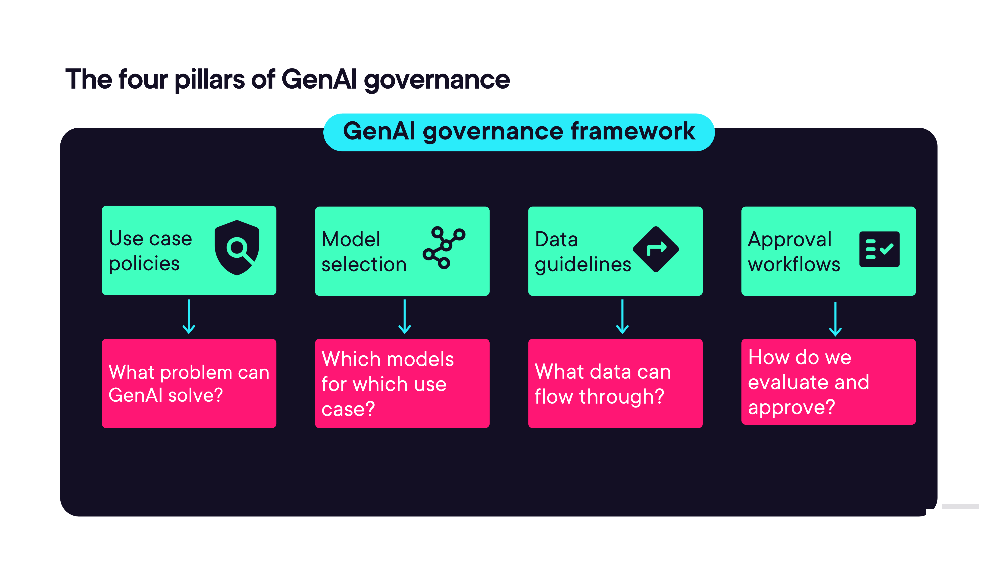

In [20]:
render_diagram(Path("assets/19-four-pillars-governance.png"))

The framework answers four questions:

1. **Use case policies** — What problem can GenAI solve? (Green: pre-approved low-risk; Yellow: requires review; Red: prohibited)
2. **Model selection** — Which models for which use cases?
3. **Data guidelines** — What data can flow through the system?
4. **Approval workflows** — How do we evaluate and approve deployments?

#### Pillar Two — Model Selection Criteria

| Factor | Question to answer |
|---|---|
| Capability | Does the model perform adequately on the target task? |
| Data residency | Where is inference performed? Does data leave the region? |
| Licensing and terms | What are the usage restrictions? Can outputs be used commercially? |
| Cost profile | Per-token cost, context window pricing, volume discounts |
| Support and SLAs | Uptime guarantees, support tiers, incident response |
| Auditability | Can you log inputs and outputs? Can you explain decisions? |

#### Pillar Three — Data Usage Guidelines

| Data category | Training? | External models? | Special requirements |
|---|---|---|---|
| Public data | Yes | Yes | None |
| Internal data | With review | Depends on model hosting | Classification labels |
| Customer data | Requires consent | Self-hosted or approved vendors only | Encryption, retention limits |
| Regulated data (PII, PHI, PCI) | No | Never to external models | Anonymization, masking, audit trail |

#### The Approval Workflow


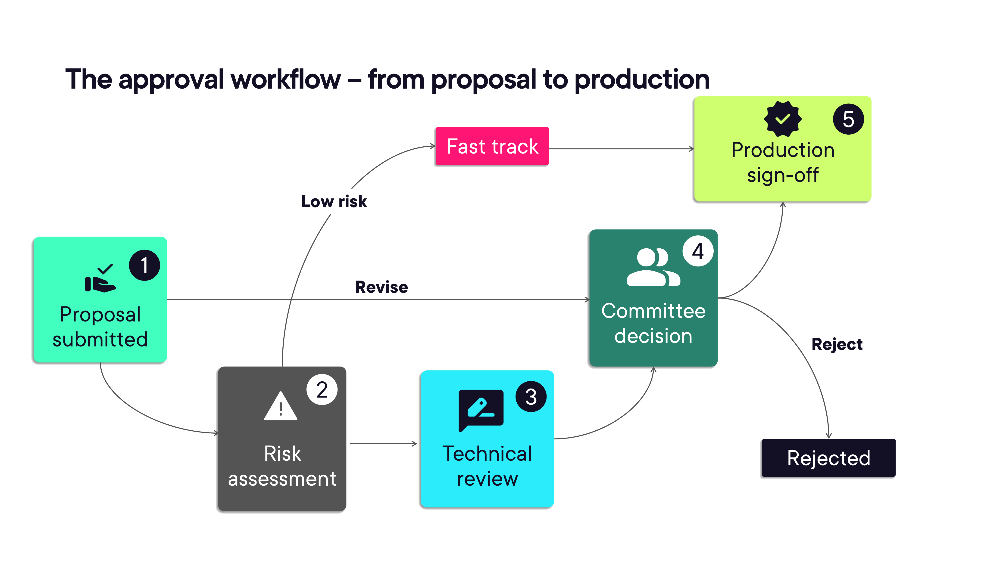

In [21]:
render_diagram(Path("assets/20-approval-workflow.png"))

The governance committee includes: Chair (VP Engineering / CTO / Chief AI Officer), Legal/Compliance, Security, Data Science/ML, and a Business stakeholder. Low-risk proposals can fast-track directly from risk assessment to production sign-off.

---

### Access Controls and Compliance Tracking

#### The Access Control Challenge for GenAI

Access control in GenAI is more than preventing breaches — it ensures accountability at every step of the model lifecycle:

| Access type | What can go wrong |
|---|---|
| Model configuration | Unauthorized prompt changes affect all users |
| Training data | Data poisoning, IP exposure |
| Evaluation results | Cherry-picked metrics hide real performance |
| Production endpoints | Direct access bypasses guardrails |
| Audit logs | Tampering destroys compliance evidence |

#### The Principle of Least Privilege

> Every user, service, and process should have only the minimum access necessary to perform their function — and no more.

Applied to GenAI platforms:


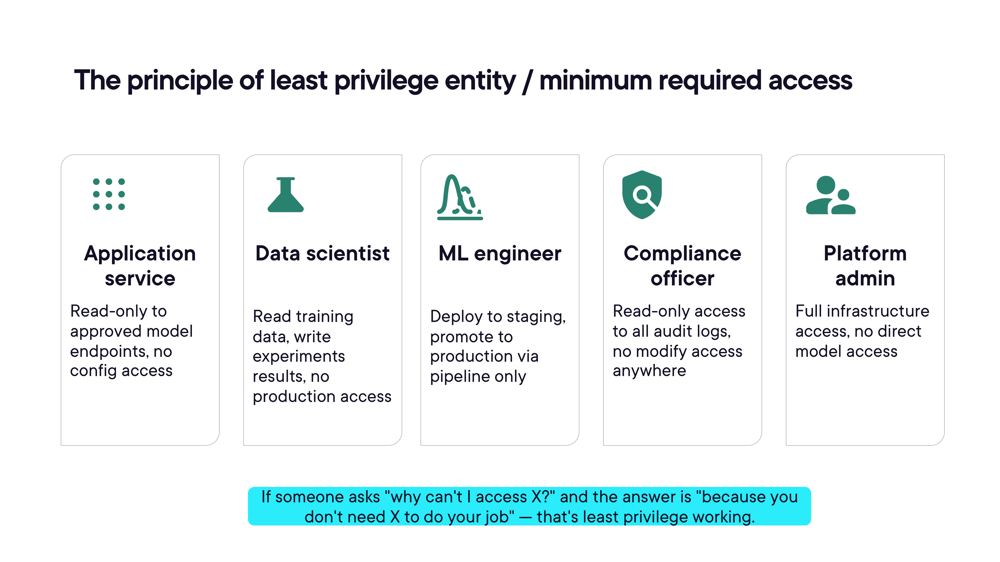

In [22]:
render_diagram(Path("assets/21-least-privilege-entities.png"))

#### Designing RBAC for GenAI Platforms

RBAC is built from three building blocks: **Roles** (what a category of user can do), **Permissions** (specific actions on specific resources), and **Assignments** (users bound to roles).

Sample roles for a GenAI platform:

| Role | Permissions |
|---|---|
| `model-viewer` | Read model catalog, view configs |
| `model-deployer` | Deploy models to staging, promote to prod |
| `prompt-author` | Create/edit prompts, submit for evaluation |
| `evaluator` | Run evaluations, view results, approve/reject |
| `data-accessor` | Read training/evaluation datasets |
| `audit-reader` | Read-only access to all audit logs |
| `platform-admin` | Full infrastructure and configuration access |

#### Separation of Duties

Separation of duties is error-catching, not distrust. Every handoff is a checkpoint:

- **Model development → Production deployment**: the builder shouldn't approve for production
- **Prompt authoring → Prompt approval**: authors submit; evaluators approve
- **Evaluation execution → Evaluation sign-off**: those who run shouldn't be the only ones who approve
- **Audit log generation → Audit log review**: log generators must not have write access to logs

#### What Auditors Actually Need

| Auditor question | What it requires |
|---|---|
| "What data was used to train this model?" | Complete data lineage — sources, transformations, versions |
| "Where did this model come from?" | Model provenance — origin, training runs, who approved deployment |
| "Why did the system produce this output?" | Decision rationale — input, retrieved context, model version, output |
| "Who had access to what, when?" | Access logs with timestamps, user IDs, actions |
| "Can you prove this hasn't been tampered with?" | Immutable audit trail with integrity verification |


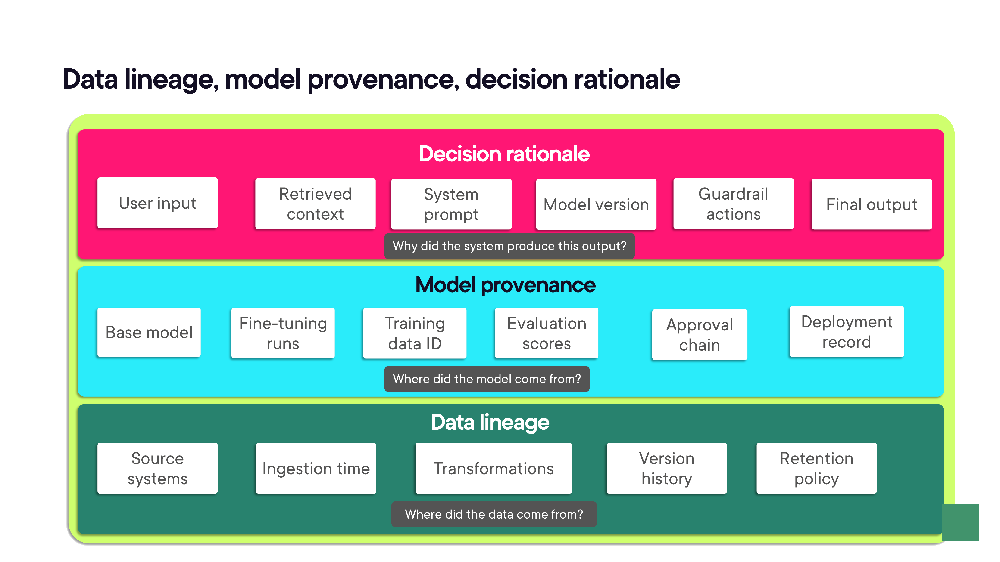

In [23]:
render_diagram(Path("assets/22-data-lineage-model-provenance.png"))

#### Building the Audit Trail — Practical Implementation

| Requirement | Implementation |
|---|---|
| **Immutability** | Write-once storage (S3 Object Lock), append-only databases, cryptographic hashing |
| **Completeness** | Structured logging at every decision point — not just errors |
| **Searchability** | Indexed by request ID, user ID, tenant ID, timestamp, model version |
| **Retention** | Policy-driven — align with regulatory requirements (often 7+ years for financial) |
| **Integrity verification** | Hash chains, periodic audits, tamper-detection alerts |

---

### Model Governance Lifecycle


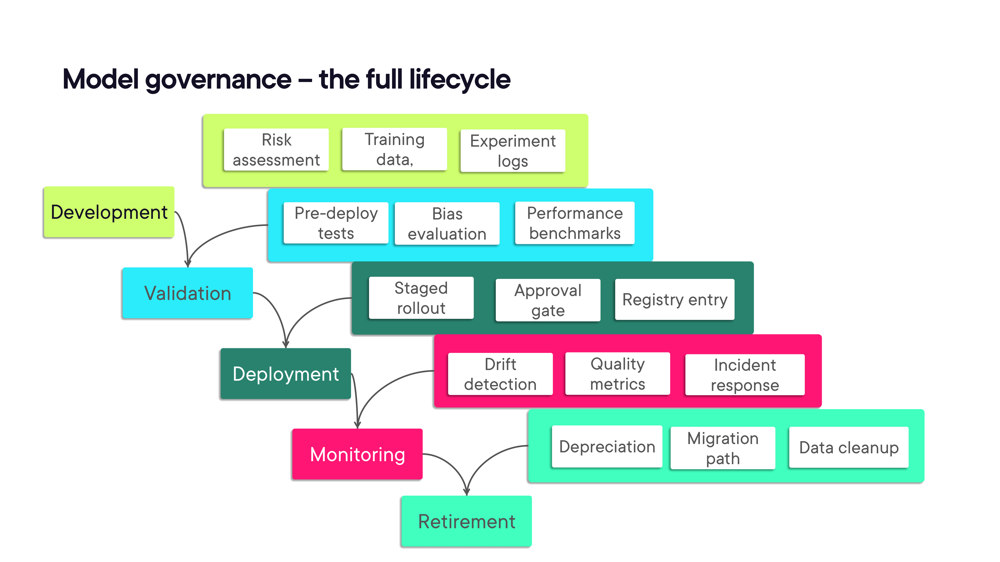

In [24]:
render_diagram(Path("assets/23-model-governance-lifecycle.png"))

The model governance lifecycle has five stages: **Development** (risk assessment, training data, experiment logs) → **Validation** (pre-deploy tests, bias evaluation, performance benchmarks) → **Deployment** (staged rollout, approval gate, registry entry) → **Monitoring** (drift detection, quality metrics, incident response) → **Retirement** (deprecation, migration path, data cleanup).

#### Tiered Risk Classification

| Tier | Risk | Characteristics | Governance requirements |
|---|---|---|---|
| Tier 1 | Low | Internal use only, no PII, non-critical decisions | Self-service deployment, automated evaluation |
| Tier 2 | Medium | Customer-facing or handles sensitive data | Human review required, enhanced monitoring |
| Tier 3 | High | Regulated industry, consequential decisions, high visibility | Full committee approval, continuous audit, incident response plan |

#### Pre-Deployment Validation

| Test category | What you are evaluating | Pass criteria |
|---|---|---|
| Functional accuracy | Does the model produce correct outputs for known inputs? | ≥ baseline threshold on held-out test set |
| Safety and guardrails | Does the model refuse harmful requests? | Zero failures on safety test suite |
| Performance | Latency, throughput, resource consumption | Within SLA requirements |
| Regression | Does the new version perform at least as well as current production? | No degradation on key metrics |
| Edge cases | How does the model handle adversarial or out-of-distribution inputs? | Graceful degradation, appropriate refusals |

#### Bias Evaluation

Bias evaluation is not optional for high-risk models — in some jurisdictions it is legally required.

| Dimension | What to measure | How to detect |
|---|---|---|
| Demographic parity | Are outcomes distributed equitably across groups? | Compare output distributions by demographic segment |
| Representation | Are all relevant groups in training data? | Audit training data composition |
| Stereotyping | Does the model reinforce harmful stereotypes? | Adversarial testing with stereotype-probing prompts |
| Performance disparity | Does accuracy vary across groups? | Disaggregated evaluation metrics |

#### Ongoing Monitoring — Post-Deployment Requirements

| Monitoring dimension | What you are watching | Alert triggers |
|---|---|---|
| Drift detection | Is input/output distribution changing? | Statistical divergence exceeds threshold |
| Quality metrics | User satisfaction, task completion, accuracy | Metrics drop below baseline |
| Latency and availability | Response time, error rates, uptime | SLA breaches |
| Safety violation | Guardrail triggers, refused requests, flagged outputs | Spike in safety events |
| Cost tracking | Token consumption, compute usage, cost per request | Budget thresholds exceeded |

#### Incident Response

| Level | Definition | Response time | Example |
|---|---|---|---|
| P1 | Critical safety or compliance violation | < 15 minutes | Model generating harmful content, data leak |
| P2 | Significant quality degradation | < 1 hour | Major accuracy drop, high error rate |
| P3 | Minor issues, no immediate impact | < 24 hours | Performance regression, cosmetic issues |

#### Model Retirement — End-of-Life Done Right

Model retirement is triggered by: performance degradation, security vulnerability, compliance requirements, a better alternative, or a business decision. The retirement process follows six steps: announce deprecation timeline (30–90 days), provide migration path, update dependent services and documentation, monitor usage until cutoff, archive artifacts and training data references, then execute cleanup while preserving the audit trail.

#### The Model Registry — Enforcing Governance Gates

The model registry is the deployment gatekeeper. A deployment pipeline checks model status before proceeding. Only models with all four checks passed — validation, bias evaluation, security review, committee approval — are permitted to deploy to production.


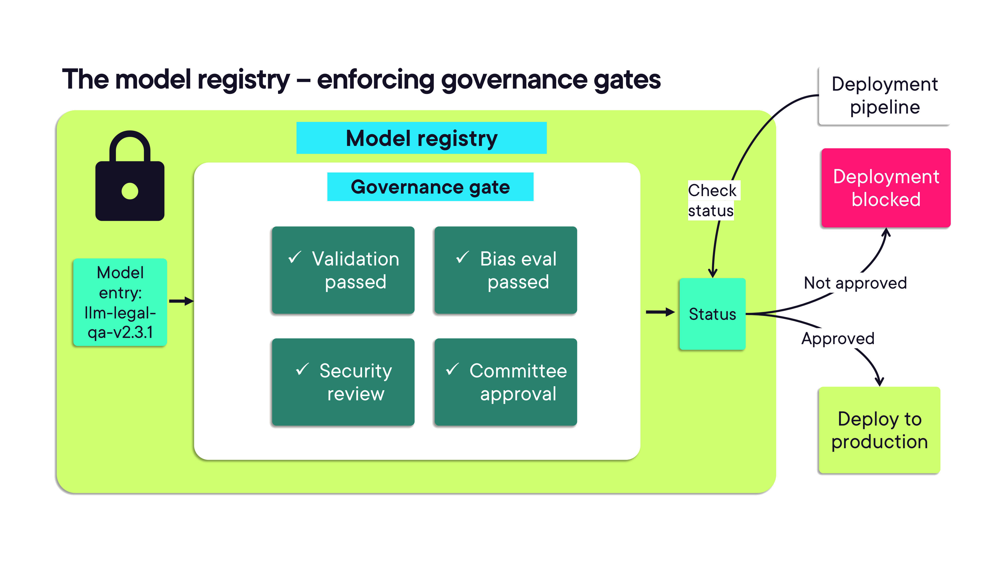

In [25]:
render_diagram(Path("assets/24-model-registry.png"))

<a id="module-04"></a>
## Module 04: Auditability and Transparency in GenAI Systems

_Covers audit requirements and immutable logging, explainability and transparency features, and compliance reporting and audit readiness._

---

### Audit Requirements and Immutable Logging

#### Why GenAI Audit is Different

In traditional software, auditing is straightforward: user action → system response → log entry. In GenAI, the chain is longer and every link matters:

```
User prompt → Retrieval context → Model reasoning → Response generation → Guardrail check
```

If any link is missing, you cannot explain what happened. This is not just a compliance concern — it makes debugging impossible.

#### Anatomy of a GenAI Audit Record

A complete audit record must capture four layers:


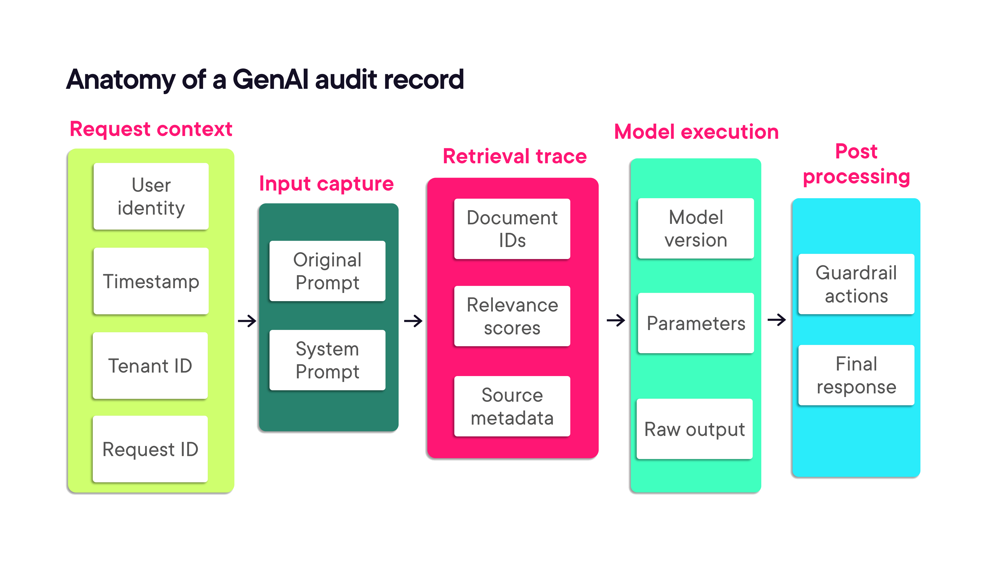

In [26]:
render_diagram(Path("assets/25-genai-audit-record-anatomy.png"))

The four layers: **Request context** (user identity, timestamp, tenant ID, request ID), **Input capture** (original prompt, system prompt), **Retrieval trace** (document IDs, relevance scores, source metadata), and **Model execution** (model version, parameters, raw output, post-processing, guardrail actions, final response).

#### The Full Decision Chain — Data Model

The audit data model links records with foreign keys so the full chain is reconstructible:

```
Request record (request_id PK, user_id, tenant_id, timestamp, original_prompt, system_prompt)
    │
    ├── 1:N → Retrieval records (retrieval_id PK, request_id FK, doc_id, chunk, score)
    │
    └── 1:N → Inference record (inference_id PK, request_id FK, model_version, params, raw_output)
                    │
                    └── N:1 → Response record (guardrail_action, final_response)
```

One request can retrieve many documents — all linked by foreign key to enable full chain reconstruction.


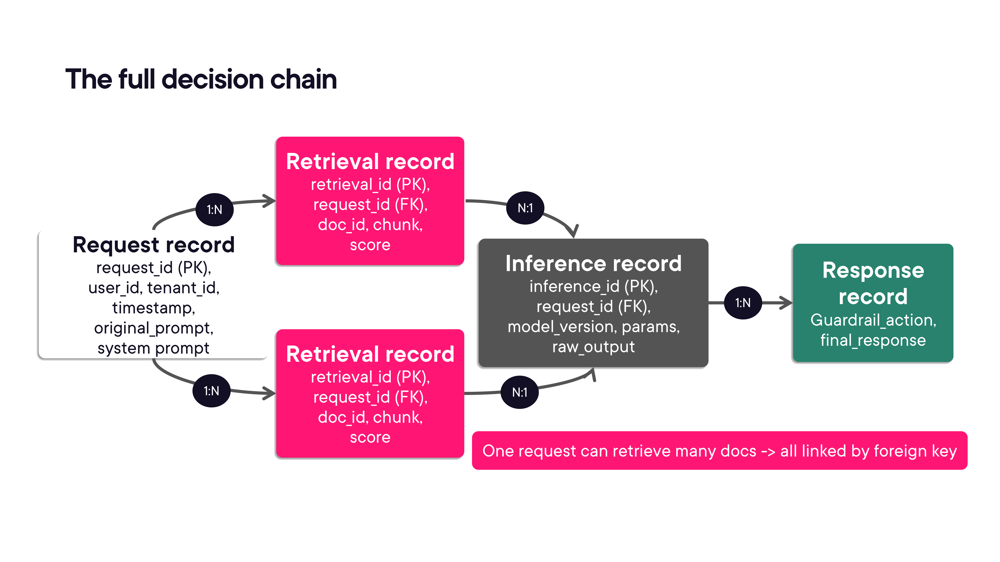

In [27]:
render_diagram(Path("assets/26-full-decision-chain.png"))

#### Immutable Logging and Storage Patterns

**Append-only stores** allow only additions — no updates or deletes. Retention policies control expiration rather than manual deletion.

**Cryptographic verification (hash chains)** make tampering detectable: each record stores a hash of its own content plus the previous record's hash. Modifying any record in the middle breaks the hash pointer, triggering an integrity check failure.


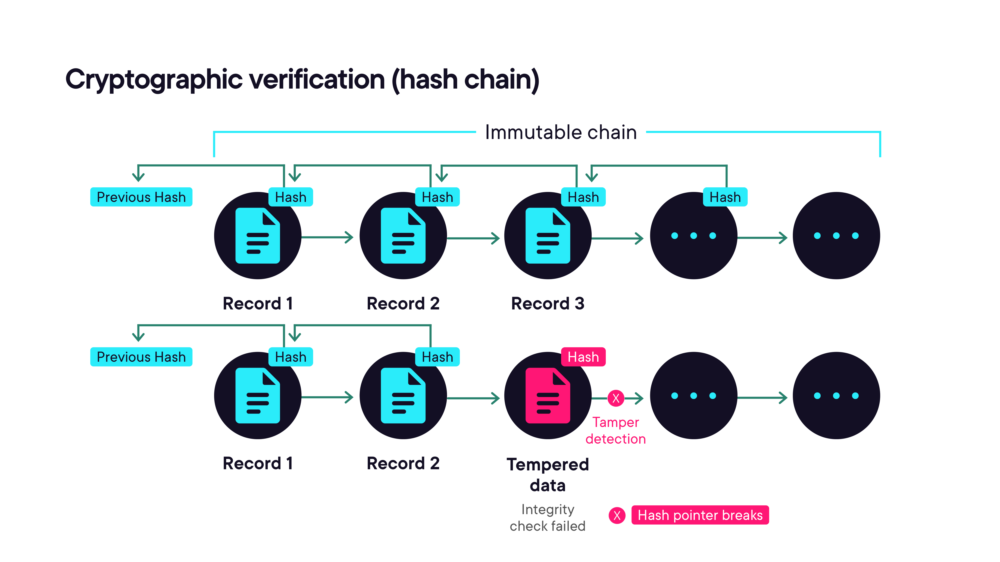

In [28]:
render_diagram(Path("assets/27-cryptographic-hash-chain.png"))

#### Designing for Performance

**Audit logging must not add latency to the request path.** The pattern is:

1. Request handler receives the request
2. It emits an audit event asynchronously (fire-and-forget to a message queue) while simultaneously continuing request processing
3. A background consumer reads from the queue and writes to the immutable audit store

**Trade-off**: there is a brief window where a crash could lose unpersisted events. Mitigations: at-least-once delivery, idempotent writes, and periodic reconciliation.


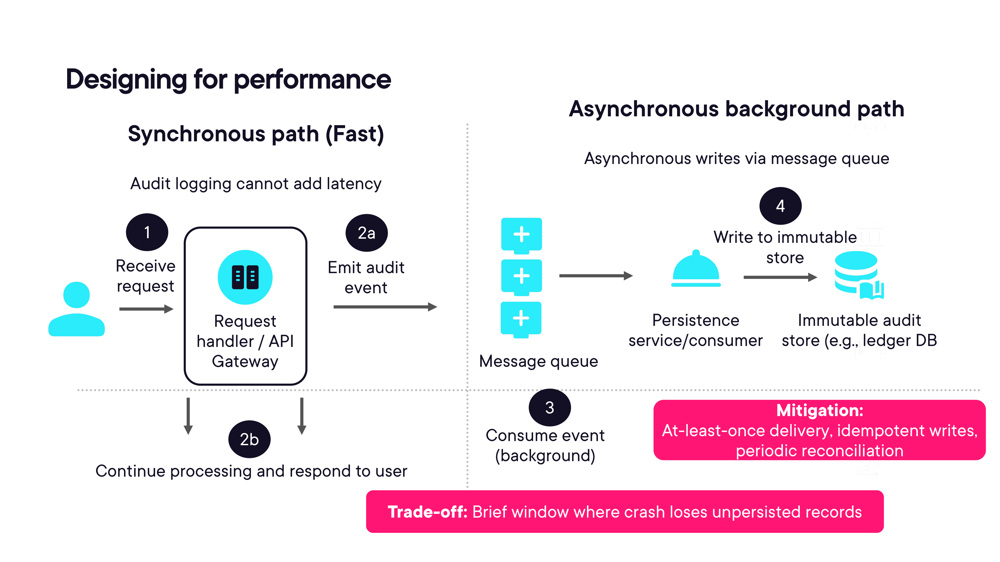

In [29]:
render_diagram(Path("assets/28-async-audit-logging.png"))

#### Retention and Storage Tiers

| Tier | Characteristics | Retention | Contents |
|---|---|---|---|
| **Hot storage** | Fast access, high-volume, queryable | 30–90 days | Retrieval traces, model outputs |
| **Warm storage** | Compressed, periodic access | 1–2 years | Archived recent records |
| **Cold storage** | Long-term retention, rare access | 7+ years | Compliance archive |

Compliance minimums: HIPAA (6 years), SOX (7 years), GDPR (purpose-limited).

---

### Explainability and Transparency Features

#### Three Audiences, Three Needs

Explainability is not one-size-fits-all. The same underlying reasoning chain is presented differently depending on the audience:

- **End users** — simplified, natural language (no percentages, no trace IDs)
- **Business users** — summarised steps with plain language confidence flags
- **Compliance/audit teams** — full trace with every step logged, numeric scores, full context

#### Retrieval Attribution

Every response grounded in retrieved documents should attribute which documents contributed to the answer, with relevance scores and source metadata — so claims can be verified against sources.

#### Reasoning Traces

For complex analytical queries (e.g., contract comparison), reasoning traces expose the model's step-by-step approach. The compliance view shows the full chain; the end-user view shows a simplified summary. Same underlying data, different presentation depth.

#### Confidence Indicators

| User-facing view | Compliance-facing view |
|---|---|
| Natural language: "Well-supported by your documents" | Numeric: 0.73 confidence score |
| "Limited sources — consider verifying" | 30-day distribution, source count, avg relevance |
| "Uncertain — verify independently" | Source agreement, partial conflict detection |

Avoid showing raw percentages to end users — "78% confidence" feels precise but isn't meaningful without context.

#### Per-Tenant Explainability Configuration

| Setting | LexCorp | NovaMed | RetailPeak |
|---|---|---|---|
| Attribution | Heavy citation: doc name, section, paragraph, score | Source verification: doc name, section, plain language | Light: "Based on product specifications" |
| Reasoning | Formal, detailed full logic chain | Simplified steps, no trace IDs | Minimal, hidden by default |
| Confidence | Numeric + reason | Plain language flags ("Well-supported" / "Verify w/ clinician") | Not shown |

---

### Compliance Reporting and Audit Readiness

#### What Auditors Actually Want

Auditors want **evidence of controls** operating consistently over time — not just documentation that controls exist.

- **Requirement**: data must be retained for a specified period and securely deleted thereafter
- **Control**: automated retention policies with system-enforced rules
- **Evidence**: deletion logs, policy configs, exception reports showing successful events

#### Common Compliance Frameworks

- **SOC 2 Type II** — operating effectiveness over a 6–12 month period
- **ISO 27001** — information security management system documentation
- **HIPAA** — PHI access logs, encryption, breach notification records
- **FedRAMP** — authorization and procurement compliance
- **PCI-DSS** — payment card data handling
- **SR 11-7** — model risk management, validation, monitoring (financial services)

#### Real-Time Policy Violation Tracking

Violations are routed to the right team at the right cadence:

- **Security team** — immediate alerts (auth failures, data breach attempts, injection attempts)
- **Compliance team** — daily digest (policy violations, access anomalies, output flags)
- **Leadership** — weekly summary (trend analysis, risk posture, incident counts)

#### Evidence Automation for Certifications

Three capabilities required: scheduled exports, chain-of-custody tracking, and tamper-evidence packaging.

<a id="module-05"></a>
## Module 05: Regulatory Landscape and Future-Proofing GenAI Systems

_Covers the emerging AI regulatory landscape, regulation-adaptive architecture patterns, and documentation practices for regulatory filings._

---

### The Emerging AI Regulatory Landscape

A governed, auditable platform operates within a fast-changing regulatory environment. Regulations are not stable — new requirements can invalidate architectural decisions made even 12 months ago. The goal is to design systems that adapt to regulation rather than require costly rework each time rules change.

#### The EU AI Act — Four Risk Tiers

| Tier | Classification | Implications |
|---|---|---|
| Unacceptable risk | Prohibited | Cannot be deployed |
| High risk | Strict obligations | Conformity assessment, registration, human oversight |
| Limited risk | Transparency required | Disclose AI-generated content, chatbot disclosure |
| Minimal risk | Mostly unregulated | Spam filters, AI-enabled video games |

**Timeline**: Prohibited practices entered into force first. General-purpose AI model obligations apply from August 2025. High-risk system requirements roll in through 2027–2030.

#### The United States — A Regulatory Patchwork

The US has no single federal AI law. Compliance requires navigating sector and state-level rules:

- **Colorado AI Act** — high-risk consequential decisions, bias audits
- **NYC Local Law 144** — automated employment tools, bias audits (in force)
- **California** — multiple laws on GenAI disclosure, training data, political deepfakes

#### Sector-Specific Rules That Still Apply

| Sector | Regulation | What it requires |
|---|---|---|
| Healthcare | HIPAA | PHI protection regardless of system type |
| Financial services | SR 11-7 | Model risk management, validation, monitoring |
| US Federal | FedRAMP, NIST AI RMF | Authorization and procurement compliance |

---

### Designing Regulation-Adaptive Architectures

#### The Problem: Building for Change, Not for Today

Compliance treated as "build once and forget" leads to costly rework when regulations change. Hard-coded rules and scattered compliance logic are brittle — a new requirement means hunting through the codebase for every affected decision point.

#### Three Patterns for Regulation-Adaptive Systems

| Pattern | Description |
|---|---|
| **Feature flags** | Region-specific behaviour toggles — enable/disable compliance behaviours per jurisdiction without code changes |
| **Configurable thresholds** | Per-jurisdiction safety settings adjustable through configuration, not deployment |
| **Pluggable compliance modules** | Modular controls that can be swapped or extended when a new regulation applies |

#### ContextIQ Across Regions

A single platform serves multiple regulatory jurisdictions through a region router that applies the correct compliance profile:


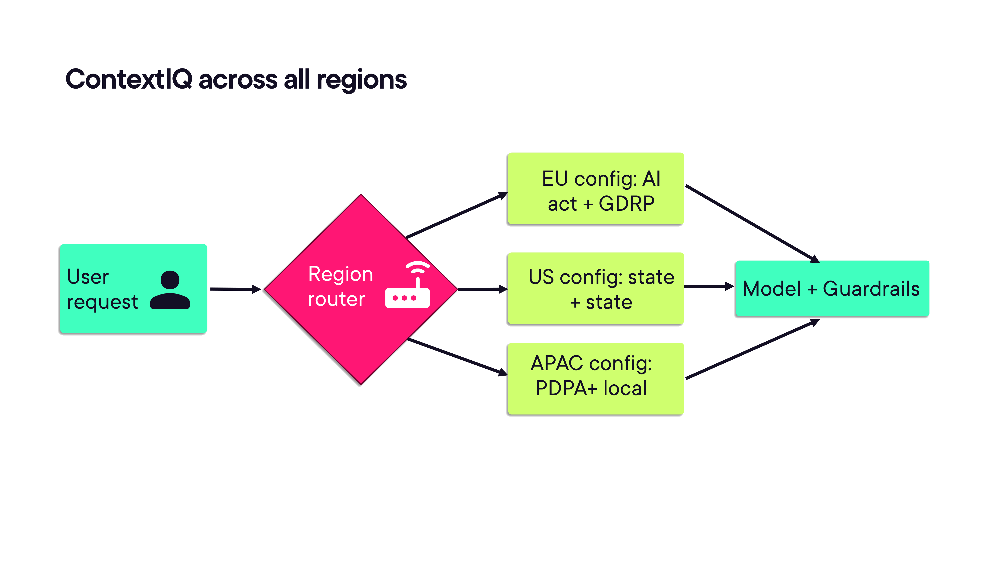

In [30]:
render_diagram(Path("assets/29-region-routing-architecture.png"))

Each region config profile bundles the applicable rules:

- **EU profile** — GDPR logging, EU data residency, human-in-the-loop for high-risk decisions, EU AI Act obligations
- **US profile** — sector check (HIPAA for healthcare tenants), state check (Colorado impact assessment)
- **APAC profile** — Singapore PDPA, Japan guidelines, local overrides

---

### Documentation Practices for Regulatory Filings

#### The Four Artifacts Regulators Ask For

| Artifact | What it covers |
|---|---|
| **System card** | What the system is and how it is built |
| **Data card** | Where the data came from, how it was processed |
| **Model card** | What the model does and doesn't do, known limitations |
| **Risk assessment** | What could go wrong and how it is prevented |

#### Documentation Belongs in the Pipeline

Documentation must not be written by hand at audit time — it must be generated automatically:

```
Code / Model / Data change → CI/CD pipeline → Regenerate cards → Versioned doc registry
```

When any component changes, the relevant cards are regenerated and committed to the versioned registry. Documentation that is generated, versioned, and kept current is evidence; documentation written manually before an audit is not.

---

### Course Summary

Five principles that apply across every module:

1. **Separate configuration from code** — behaviour changes without deployments
2. **Log everything, immutably** — evidence is non-negotiable
3. **Document as code** — artifacts generated, versioned, and current
4. **Treat compliance as architecture** — designed in, not bolted on
5. **Maximise team self-service** — governance that teams route around is no governance at all